In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv(r"sampled_data_1.csv")
df_sample = df.sort_values(by='Start_Time', ascending=False).head(10000)

In [4]:
# some preprocessing on this data 
print("first 5 row",df_sample.head())
print("************************************")

print("last 5 rows",df_sample.tail())
print("************************************")

print(df_sample.info())
print("************************************")

print("statistical properties: ",df_sample.describe())
print("************************************")

first 5 row              ID   Source  Severity Start_Time End_Time  Start_Lat   Start_Lng  \
5788  A-3669037  Source1         2    59:55.0  07:42.0  40.183910  -74.723295   
811   A-3666997  Source1         2    59:35.0  48:07.0  33.907674  -84.476467   
1026  A-3676409  Source1         2    59:34.0  20:05.0  33.704783 -117.855674   
1027  A-3669269  Source1         2    59:31.0  37:34.0  39.691894 -105.809039   
285   A-3677429  Source1         2    59:30.0  14:00.0  37.971894  -75.532112   

        End_Lat     End_Lng  Distance(mi)  ... Roundabout Station   Stop  \
5788  40.184280  -74.727496         0.223  ...      False   False  False   
811   33.928115  -84.488257         1.566  ...      False   False  False   
1026  33.695667 -117.864687         0.816  ...      False   False  False   
1027  39.693360 -105.820312         0.608  ...      False   False  False   
285   37.948828  -75.538797         1.635  ...      False   False  False   

     Traffic_Calming Traffic_Signal Turning_

In [5]:
#  EDA (some cleaning for data)
print("size of data: ", df_sample.shape)
print("************************************")
print("type of data: ", df_sample.dtypes)
print("************************************")
print(df_sample.isnull().sum())
print("************************************")
print(df.duplicated().sum())

size of data:  (10000, 46)
************************************
type of data:  ID                        object
Source                    object
Severity                   int64
Start_Time                object
End_Time                  object
Start_Lat                float64
Start_Lng                float64
End_Lat                  float64
End_Lng                  float64
Distance(mi)             float64
Description               object
Street                    object
City                      object
County                    object
State                     object
Zipcode                   object
Country                   object
Timezone                  object
Airport_Code              object
Weather_Timestamp         object
Temperature(F)           float64
Wind_Chill(F)            float64
Humidity(%)              float64
Pressure(in)             float64
Visibility(mi)           float64
Wind_Direction            object
Wind_Speed(mph)          float64
Precipitation(in)        float

In [6]:
df_sample.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='object')

In [7]:
# convert 'Start_Time' to datetime
df_sample['Start_Time'] = pd.to_datetime(df_sample['Start_Time'], errors='coerce')
df_sample['End_Time'] = pd.to_datetime(df_sample['End_Time'], errors='coerce')

df_sample['Duration'] = (df_sample['End_Time'] - df_sample['Start_Time']).dt.total_seconds()

df_sample['Day_of_Week'] = df_sample['Start_Time'].dt.day_name()
df_sample['Month'] = df_sample['Start_Time'].dt.month
df_sample['Year'] = df_sample['Start_Time'].dt.year

C:\Users\DELL\AppData\Local\Temp\ipykernel_14340\3477692450.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample['Start_Time'] = pd.to_datetime(df_sample['Start_Time'], errors='coerce')
C:\Users\DELL\AppData\Local\Temp\ipykernel_14340\3477692450.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample['End_Time'] = pd.to_datetime(df_sample['End_Time'], errors='coerce')


In [8]:
# drop columns End-lat and End-lon
df_sample.drop(columns=['End_Lat', 'End_Lng', 'Precipitation(in)'], inplace=True)

In [9]:
columns_to_impute = [
    'Distance(mi)', 
    'Temperature(F)', 
    'Wind_Chill(F)', 
    'Humidity(%)', 
    'Pressure(in)', 
    'Visibility(mi)'
]

existing_columns = [col for col in columns_to_impute if col in df_sample.columns]
column_means = df_sample[existing_columns].mean()
df_sample[existing_columns] = df_sample[existing_columns].fillna(column_means)

df_sample['Distance(mi)'].value_counts()

Distance(mi)
0.022    70
0.020    66
0.024    64
0.017    61
0.028    61
         ..
7.682     1
0.843     1
4.933     1
1.925     1
2.969     1
Name: count, Length: 2315, dtype: int64

In [10]:
# to check cleaning data 
df_sample.isnull().sum()

ID                          0
Source                      0
Severity                    0
Start_Time               1981
End_Time                 1963
Start_Lat                   0
Start_Lng                   0
Distance(mi)                0
Description                 0
Street                     28
City                        0
County                      0
State                       0
Zipcode                     0
Country                     0
Timezone                    3
Airport_Code               26
Weather_Timestamp         282
Temperature(F)              0
Wind_Chill(F)               0
Humidity(%)                 0
Pressure(in)                0
Visibility(mi)              0
Wind_Direction            378
Wind_Speed(mph)           378
Weather_Condition         328
Amenity                     0
Bump                        0
Crossing                    0
Give_Way                    0
Junction                    0
No_Exit                     0
Railway                     0
Roundabout

In [11]:
df_sample['Wind_Direction'].value_counts()

Wind_Direction
CALM    1227
S        854
W        744
SSE      605
SSW      601
VAR      590
WSW      529
N        524
E        506
SE       505
SW       504
NW       435
WNW      425
NNW      393
NE       353
NNE      304
ESE      300
ENE      223
Name: count, dtype: int64

In [12]:
# Step 1: Calculate the median excluding zeros
non_zero_median = df_sample.loc[df_sample['Wind_Speed(mph)'] != 0, 'Wind_Speed(mph)'].median()

# Step 2: Replace zeros with that median
df_sample.loc[df_sample['Wind_Speed(mph)'] == 0, 'Wind_Speed(mph)'] = non_zero_median

df_sample['Wind_Speed(mph)'].value_counts()

Wind_Speed(mph)
8.0     2106
6.0      875
7.0      866
5.0      820
3.0      814
9.0      747
10.0     658
12.0     573
13.0     515
14.0     414
15.0     316
16.0     222
17.0     183
18.0     103
20.0      87
22.0      62
23.0      54
21.0      49
26.0      36
24.0      30
25.0      23
29.0      18
28.0      11
31.0       8
36.0       7
32.0       7
44.0       4
39.0       4
30.0       3
37.0       2
45.0       2
33.0       1
66.0       1
40.0       1
Name: count, dtype: int64

In [13]:
df_sample.groupby('Wind_Direction')['Wind_Speed(mph)'].value_counts()

Wind_Direction  Wind_Speed(mph)
CALM            8.0                1227
E               5.0                  76
                8.0                  73
                6.0                  69
                7.0                  59
                                   ... 
WSW             18.0                  1
                20.0                  1
                24.0                  1
                25.0                  1
                28.0                  1
Name: count, Length: 334, dtype: int64

In [14]:
# feature engineering
#1-   Time-Based Features
# First ensure the columns exist
if 'Start_Time' in df_sample.columns:
    # Create hour and day_of_week columns if they don't exist
    if 'hour' not in df_sample.columns:
        df_sample['hour'] = pd.to_datetime(df_sample['Start_Time']).dt.hour
    
    if 'day_of_week' not in df_sample.columns:
        df_sample['day_of_week'] = pd.to_datetime(df_sample['Start_Time']).dt.dayofweek
    
    # Now apply your transformations
    df_sample['time_of_day'] = df_sample['hour'].apply(time_of_day)
    df_sample['is_weekend'] = df_sample['day_of_week'].isin([5, 6]).astype(int)
else:
    print("Error: 'Start_Time' column not found in DataFrame")

NameError: name 'time_of_day' is not defined

In [ ]:
# 2. Weather Condition Features
# Simplify weather conditions into broader categories
def categorize_weather(condition):
    if pd.isna(condition):
        return 'Unknown'
    condition = condition.lower()
    if 'rain' in condition or 'shower' in condition:
        return 'Rainy'
    elif 'snow' in condition or 'ice' in condition or 'sleet' in condition:
        return 'Snowy'
    elif 'fog' in condition or 'haze' in condition or 'mist' in condition:
        return 'Foggy'
    elif 'cloud' in condition:
        return 'Cloudy'
    elif 'clear' in condition or 'fair' in condition:
        return 'Clear'
    elif 'wind' in condition:
        return 'Windy'
    else:
        return 'Other'
    
df_sample['weather_category'] = df_sample['Weather_Condition'].apply(categorize_weather)

In [ ]:
# 3. Location-Based Features
# Calculate distance between start and end points (approximate)
df_sample['distance_km'] = df_sample['Distance(mi)'] * 1.60934

# Create region feature based on state
def get_region(state):
    northeast = ['CT', 'ME', 'MA', 'NH', 'RI', 'VT', 'NJ', 'NY', 'PA']
    midwest = ['IL', 'IN', 'MI', 'OH', 'WI', 'IA', 'KS', 'MN', 'MO', 'NE', 'ND', 'SD']
    south = ['DE', 'FL', 'GA', 'MD', 'NC', 'SC', 'VA', 'DC', 'WV', 'AL', 'KY', 'MS', 'TN', 'AR', 'LA', 'OK', 'TX']
    west = ['AZ', 'CO', 'ID', 'MT', 'NV', 'NM', 'UT', 'WY', 'AK', 'CA', 'HI', 'OR', 'WA']
    
    if state in northeast:
        return 'Northeast'
    elif state in midwest:
        return 'Midwest'
    elif state in south:
        return 'South'
    elif state in west:
        return 'West'
    else:
        return 'Unknown'
    
df_sample['region'] = df_sample['State'].apply(get_region)

In [ ]:
# 4. Road Condition Features
# Create binary flags for road features
road_features = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 
                 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 
                 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop']

for feature in road_features:
    df_sample[f'has_{feature.lower()}'] = df_sample[feature].astype(int)

# Count of road features at accident location
df_sample['road_feature_count'] = df_sample[road_features].sum(axis=1)

In [ ]:
# 5. Severity Features
# Create severity categories
def categorize_severity(severity):
    if severity == 1:
        return 'Low'
    elif severity == 2:
        return 'Medium'
    elif severity == 3:
        return 'High'
    else:
        return 'Very High'
    
df_sample['severity_category'] = df_sample['Severity'].apply(categorize_severity)

# Interaction between weather and severity
df_sample['weather_severity'] = df_sample['weather_category'] + '_' + df_sample['severity_category']

In [ ]:
# 6. Temporal Aggregation Features
# Calculate accidents per hour (for normalization)
accidents_per_hour = df_sample.groupby('hour').size().reset_index(name='accidents_per_hour')
df_sample = df_sample.merge(accidents_per_hour, on='hour', how='left')

# Calculate severity by hour
severity_by_hour = df_sample.groupby('hour')['Severity'].mean().reset_index(name='avg_severity_by_hour')
df_sample = df_sample.merge(severity_by_hour, on='hour', how='left')

C:\Users\Rana\AppData\Local\Temp\ipykernel_73852\2102543875.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sample, x='time_of_day', order=['Morning', 'Afternoon', 'Evening', 'Night'],


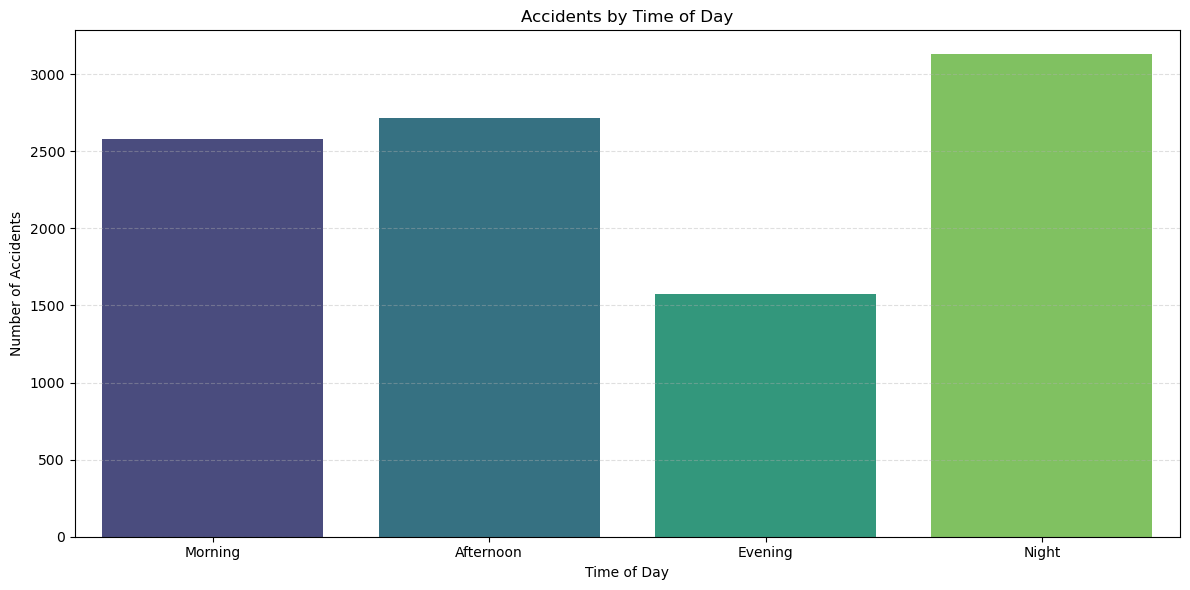

C:\Users\Rana\AppData\Local\Temp\ipykernel_73852\2102543875.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sample, x='weather_category',


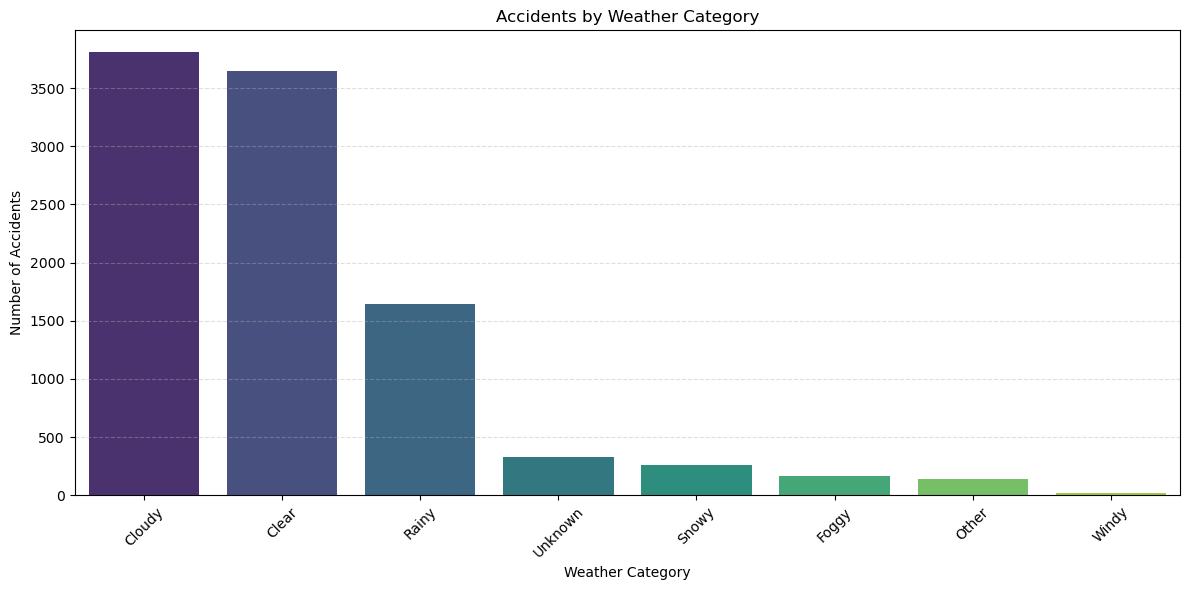

C:\Users\Rana\AppData\Local\Temp\ipykernel_73852\2102543875.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sample, x='region', y='Severity', palette='viridis')


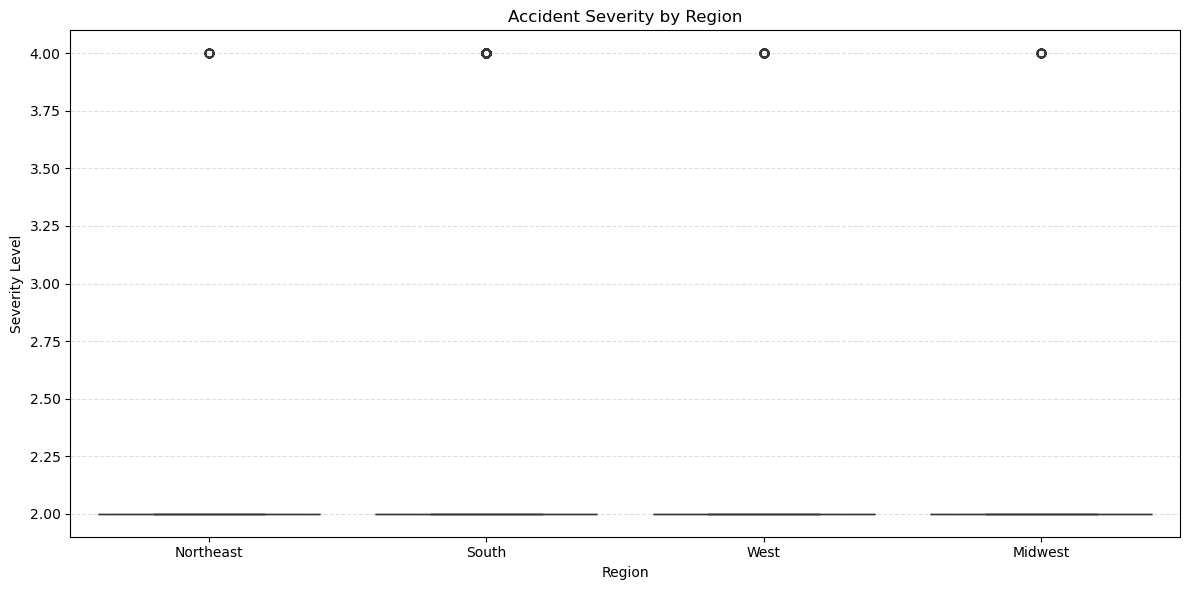

In [ ]:
# 7-visualizing for feature engineering 
import matplotlib.pyplot as plt
import seaborn as sns
# Plot accidents by time of day
plt.figure(figsize=(12, 6))
sns.countplot(data=df_sample, x='time_of_day', order=['Morning', 'Afternoon', 'Evening', 'Night'], 
              palette='viridis')
plt.title('Accidents by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Number of Accidents')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Plot accidents by weather category
plt.figure(figsize=(12, 6))
sns.countplot(data=df_sample, x='weather_category', 
              order=df_sample['weather_category'].value_counts().index,
              palette='viridis')
plt.title('Accidents by Weather Category')
plt.xlabel('Weather Category')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Plot severity by region
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_sample, x='region', y='Severity', palette='viridis')
plt.title('Accident Severity by Region')
plt.xlabel('Region')
plt.ylabel('Severity Level')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# 8. Feature Selection
selected_features = [
    'hour', 'day_of_week', 'month', 'time_of_day', 'is_weekend',
    'weather_category', 'region', 'distance_km', 'road_feature_count',
    'severity_category', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)',
    'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 
    'has_amenity', 'has_bump', 'has_crossing', 'has_give_way', 
    'has_junction', 'has_no_exit', 'has_railway', 'has_roundabout',
    'has_station', 'has_stop', 'has_traffic_calming', 
    'has_traffic_signal', 'has_turning_loop',
    'accidents_per_hour', 'avg_severity_by_hour'
]

# Target variable
target = 'Severity'

Benefits of This Feature Engineering
Improved Predictive Power: The new features capture more nuanced patterns in accident data

Enhanced Interpretability: Categorical groupings make patterns easier to understand

Better Normalization: Features like accidents-per-hour account for baseline traffic patterns

Interaction Effects: Combined features (like weather-severity) capture complex relationships

Reduced Dime


# The Most Hours 12 -> 6 pm
# The Most Hour -> 3 pm

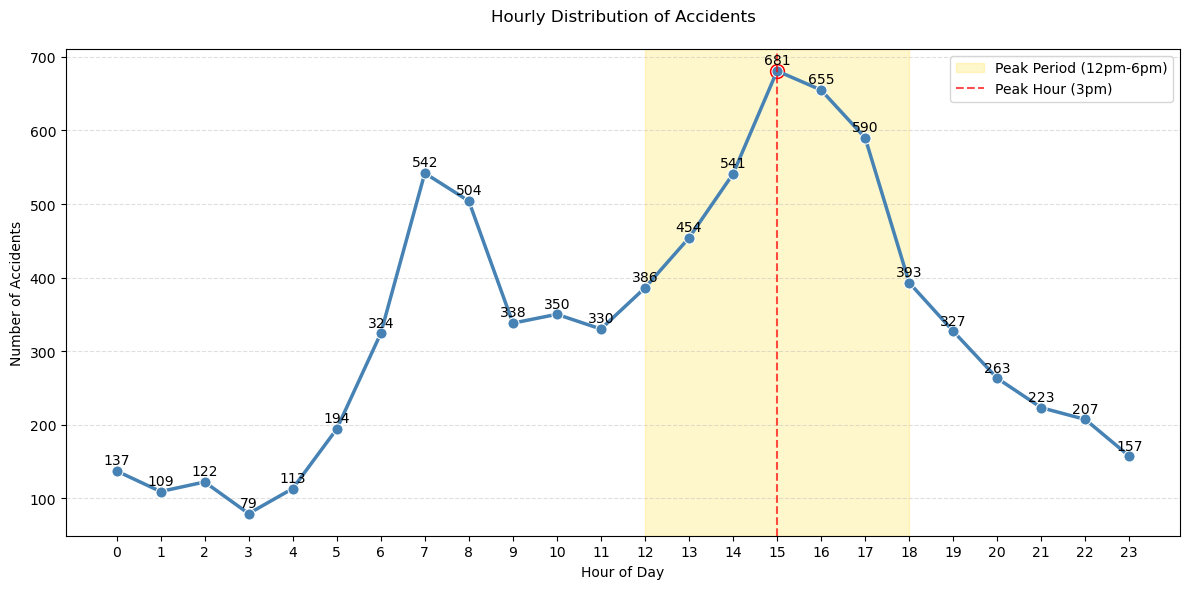

In [ ]:
# line plot
import matplotlib.pyplot as plt
import seaborn as sns

# Extract hour from Start_Time if not already done
df_sample['hour'] = df_sample['Start_Time'].dt.hour

# Create the line plot
plt.figure(figsize=(12, 6))

# Calculate hourly counts
hourly_counts = df_sample['hour'].value_counts().sort_index()

# Create line plot with markers
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, 
             marker='o', color='steelblue', linewidth=2.5, markersize=8)

# Highlight peak hours (12pm-6pm)
plt.axvspan(12, 18, color='gold', alpha=0.2, label='Peak Period (12pm-6pm)')

# Highlight the peak hour (3pm)
plt.axvline(x=15, color='red', linestyle='--', alpha=0.7, label='Peak Hour (3pm)')
plt.scatter(x=15, y=hourly_counts[15], color='red', s=100)

# Customize the plot
plt.title("Hourly Distribution of Accidents", pad=20)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Accidents")
plt.xticks(range(24))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Add value labels at each point
for hour, count in hourly_counts.items():
    plt.text(hour, count+5, str(count), ha='center', va='bottom')

plt.tight_layout()
plt.show()

<Figure size 1400x1000 with 0 Axes>

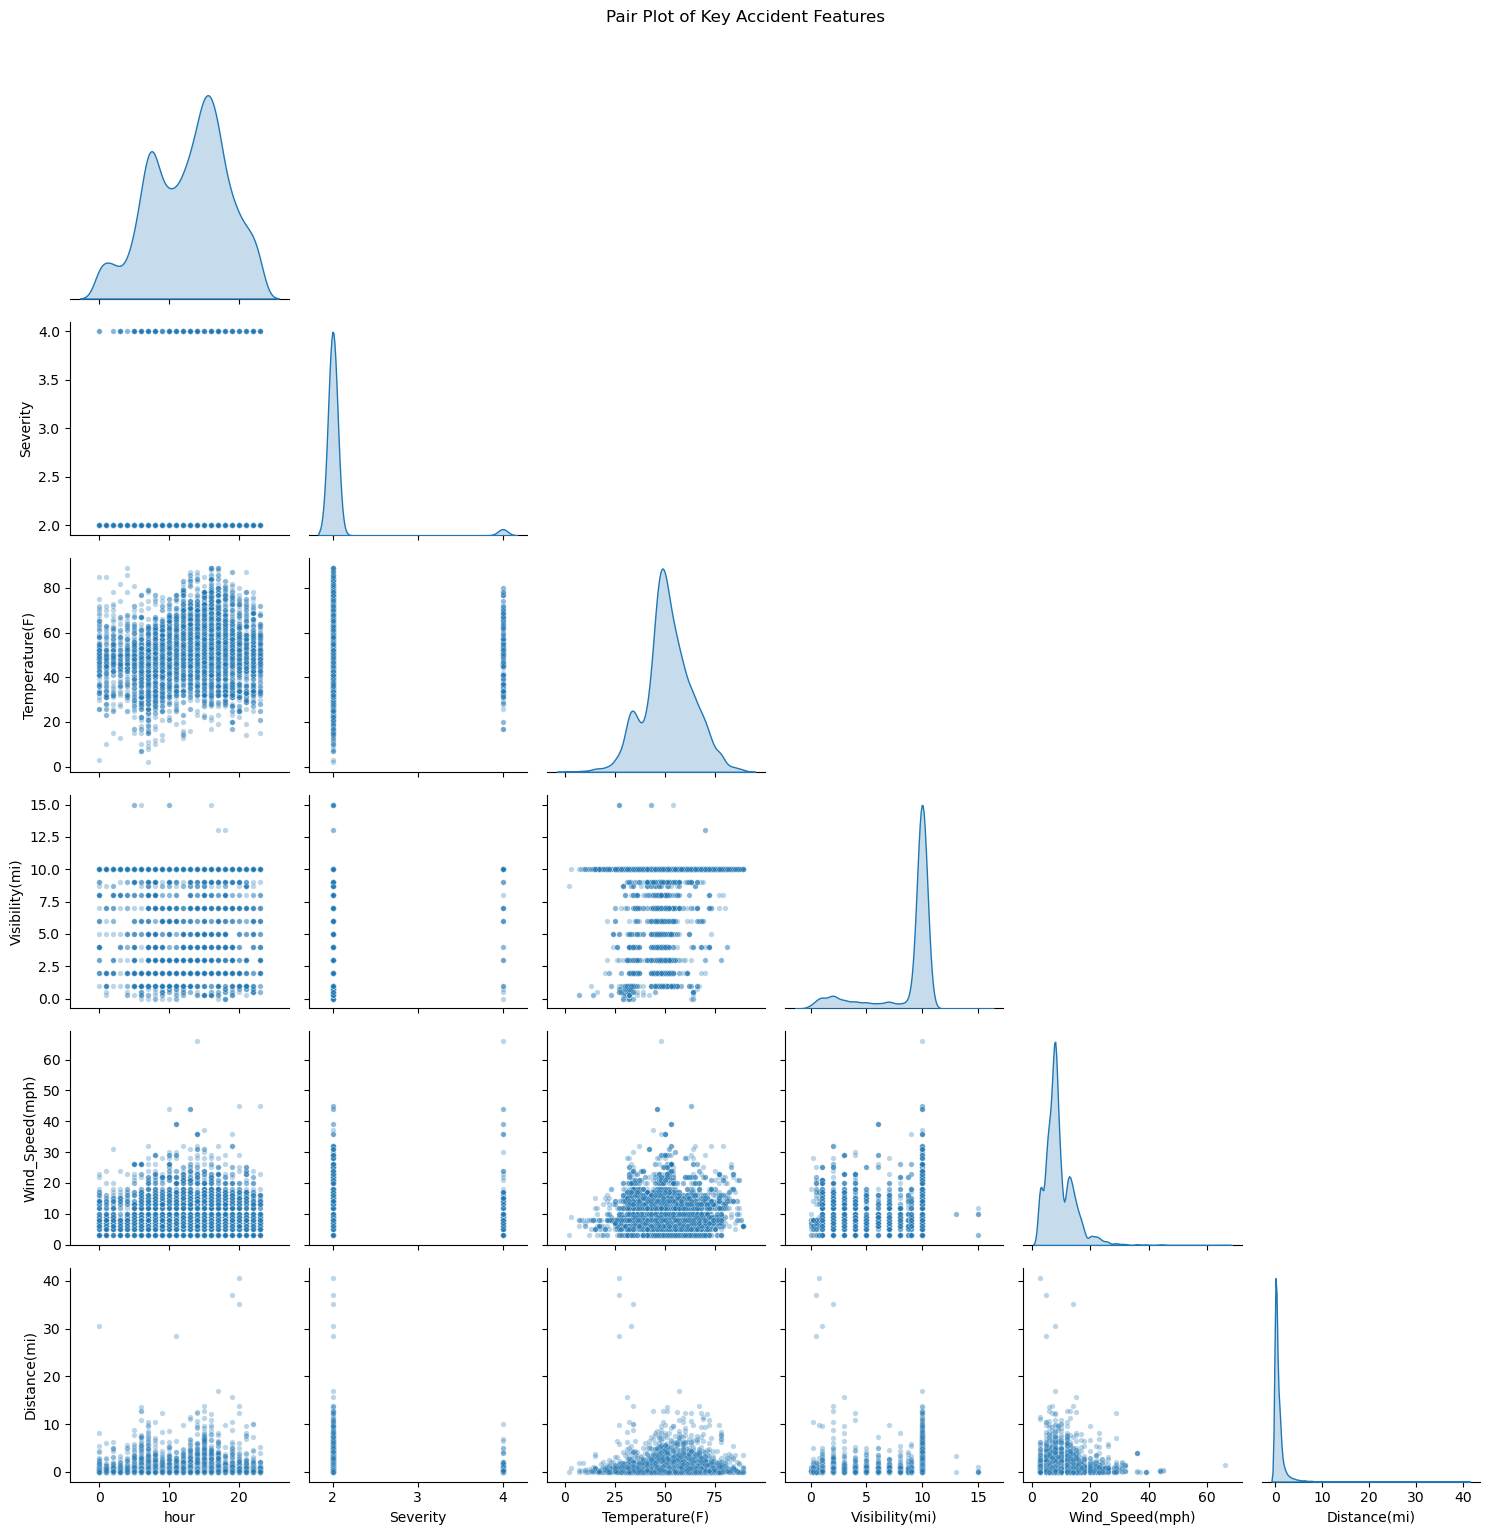

In [ ]:
# pair plot
# Select key numerical features for pair plot
pair_plot_features = ['hour', 'Severity', 'Temperature(F)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Distance(mi)']

plt.figure(figsize=(14, 10))
sns.pairplot(df_sample[pair_plot_features].dropna(), 
             diag_kind='kde',  # Use kernel density for diagonals
             plot_kws={'alpha': 0.3, 's': 15},  # Scatterplot settings
             corner=True)  # Show only lower triangle
plt.suptitle('Pair Plot of Key Accident Features', y=1.02)
plt.tight_layout()
plt.show()

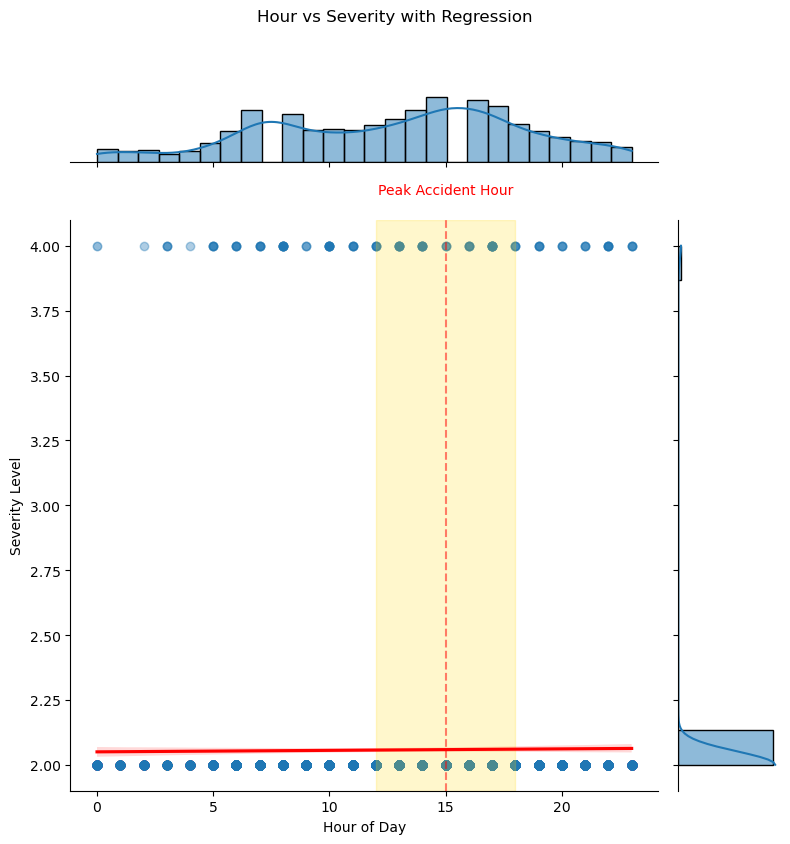

In [ ]:
# joint plot
# More advanced joint plot with regression
g = sns.jointplot(data=df_sample, 
                 x='hour', 
                 y='Severity',
                 kind='reg',  # Adds regression line
                 scatter_kws={'alpha': 0.2},
                 line_kws={'color': 'red'},
                 height=8)

# Highlight peak period
g.ax_joint.axvspan(12, 18, color='gold', alpha=0.2)
g.ax_joint.axvline(x=15, color='red', linestyle='--', alpha=0.5)

# Add distribution insights
g.ax_joint.text(15, df_sample['Severity'].max()+0.2, 
               'Peak Accident Hour', 
               ha='center', color='red')

g.ax_joint.set_xlabel('Hour of Day')
g.ax_joint.set_ylabel('Severity Level')
g.fig.suptitle('Hour vs Severity with Regression', y=1.05)

plt.tight_layout()
plt.show()

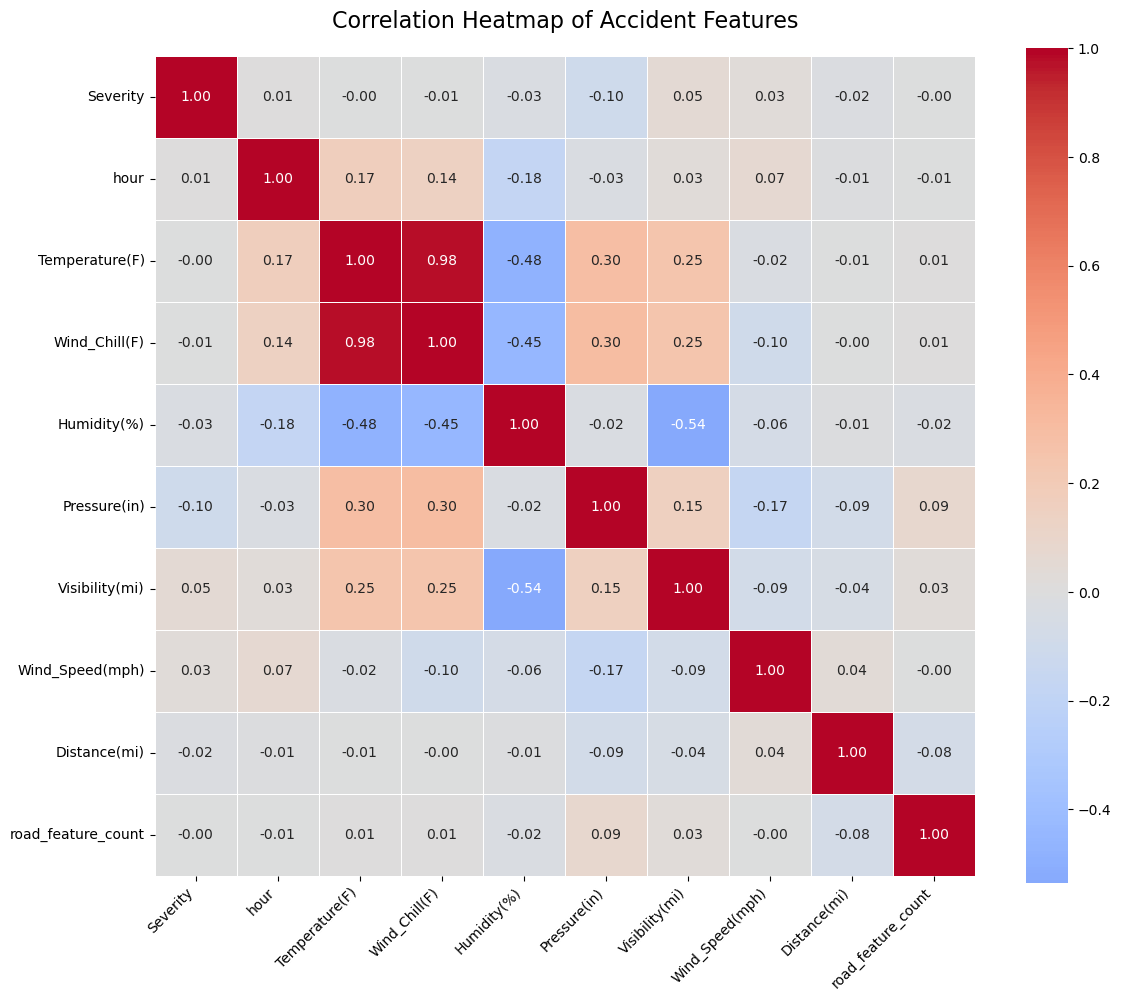

In [ ]:
# correlation plot
# Select numerical features for correlation analysis
numerical_features = ['Severity', 'hour', 'Temperature(F)', 'Wind_Chill(F)', 
                     'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 
                     'Wind_Speed(mph)', 'Distance(mi)', 'road_feature_count']

# Calculate correlation matrix
corr_matrix = df_sample[numerical_features].corr()

# Create heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            annot=True,       # Show correlation values
            fmt=".2f",       # 2 decimal places
            cmap='coolwarm',  # Color scheme
            center=0,        # Center at 0 correlation
            linewidths=0.5,  # Line width between cells
            linecolor='white',  # Line color between cells
            square=True)     # Square cells

# Customize plot
plt.title('Correlation Heatmap of Accident Features', pad=20, fontsize=16)
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels
plt.yticks(rotation=0)  # Keep y-axis labels horizontal
plt.tight_layout()
plt.show()

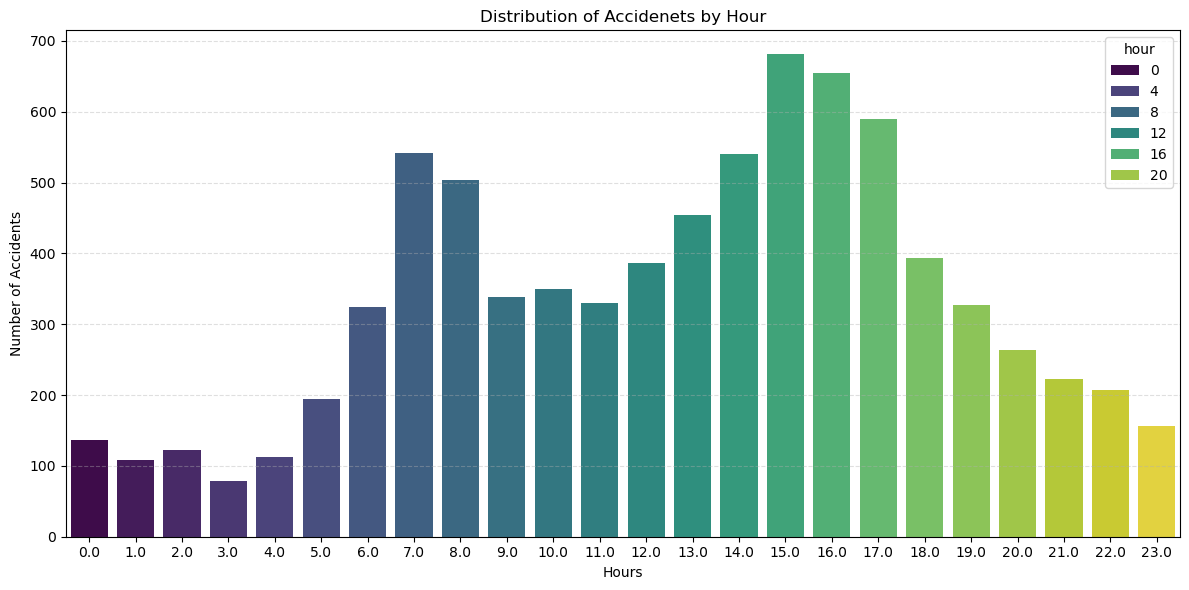

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
df_sample['hour'] = df_sample['Start_Time'].dt.hour
plt.figure(figsize = (12 , 6))
sns.countplot(data = df_sample , x= "hour" , hue = "hour" , palette = 'viridis' , legend = True)
plt.title("Distribution of Accidenets by Hour")
plt.xlabel("Hours")
plt.ylabel("Number of Accidents")
plt.grid(axis = 'y' , linestyle = '--' , alpha =0.4)

C:\Users\Rana\AppData\Local\Temp\ipykernel_73852\1382313568.py:184: FutureWarning:

'H' is deprecated and will be removed in a future version, please use 'h' instead.

C:\Users\Rana\AppData\Local\Temp\ipykernel_73852\1382313568.py:161: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




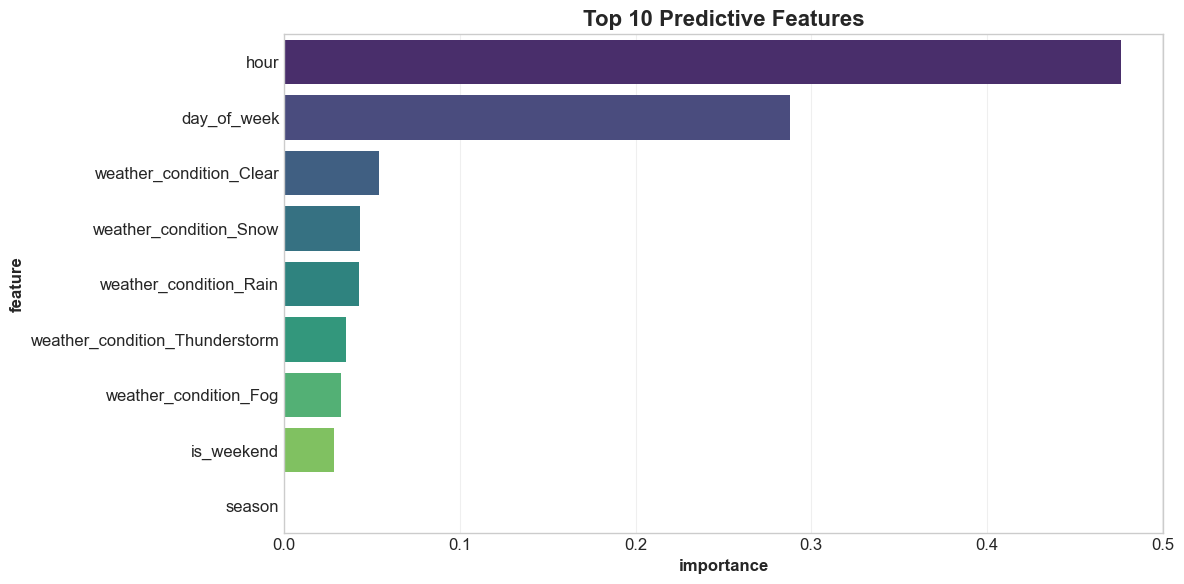


PREDICTIVE DECISION SUPPORT REPORT

Model Performance (MAE): 1.28

TOP RISK SCENARIOS:

1. Rain on weekend (Severity: 4.67)
   Time: 11:00-12:00
   Recommended Actions:
    - Increase patrols by 40% during 11:00-12:00
    - Pre-stage emergency equipment in central locations
    - Activate Rain response protocol

2. Fog on weekday (Severity: 4.59)
   Time: 23:00-24:00
   Recommended Actions:
    - Increase patrols by 40% during 23:00-24:00
    - Pre-stage emergency equipment in central locations
    - Activate Fog response protocol

3. Snow on weekend (Severity: 4.48)
   Time: 10:00-11:00
   Recommended Actions:
    - Increase patrols by 40% during 10:00-11:00
    - Pre-stage emergency equipment in central locations
    - Activate Snow response protocol

4. Fog on weekend (Severity: 4.4)
   Time: 08:00-09:00
   Recommended Actions:
    - Increase patrols by 40% during 08:00-09:00
    - Pre-stage emergency equipment in central locations
    - Activate Fog response protocol

5. Thunderst

In [ ]:
# summery and recommendations
"""
COMPLETE WEATHER IMPACT ANALYTICS SUITE WITH PREDICTIVE MODELING
----------------------------------------------------------------
1. Data Preprocessing
2. Exploratory Analysis
3. Predictive Modeling
4. Decision Optimization
"""

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# ======================
# 1. PREDICTIVE MODELING
# ======================
def build_predictive_model(df):
    """
    Build severity prediction model with feature importance analysis
    Returns trained model and validation metrics
    """
    # Feature Engineering
    df['day_of_week'] = df['timestamp'].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)
    df['season'] = df['timestamp'].dt.month%12 // 3 + 1
    
    # Prepare features/target
    features = pd.get_dummies(df[['hour', 'day_of_week', 'is_weekend', 
                                'season', 'weather_condition']])
    target = df['severity']
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.2, random_state=42)
    
    # Model training
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    # Evaluation
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    
    # Feature importance
    importance = pd.DataFrame({
        'feature': features.columns,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    return model, mae, importance

# ======================
# 2. SCENARIO SIMULATION
# ======================
def simulate_scenarios(model, weather_conditions):
    """
    Predict severity under different weather scenarios
    Returns DataFrame with predicted severities
    """
    scenarios = []
    for hour in range(24):
        for weather in weather_conditions:
            for is_weekend in [0, 1]:
                scenario = {
                    'hour': hour,
                    'weather_condition': weather,
                    'is_weekend': is_weekend,
                    'day_of_week': 5 if is_weekend else 0,
                    'season': 2  # Assume summer season
                }
                scenarios.append(scenario)
    
    scenario_df = pd.DataFrame(scenarios)
    features = pd.get_dummies(scenario_df)
    
    # Align columns with training data
    missing_cols = set(model.feature_names_in_) - set(features.columns)
    for col in missing_cols:
        features[col] = 0
    features = features[model.feature_names_in_]
    
    scenario_df['predicted_severity'] = model.predict(features)
    return scenario_df

# ======================
# 3. DECISION OPTIMIZATION
# ======================
def generate_optimized_recommendations(scenario_results, model_metrics):
    """
    Generate data-driven recommendations based on predictive insights
    """
    # Find highest risk scenarios
    high_risk = scenario_results.sort_values('predicted_severity', ascending=False).head(5)
    
    # Generate recommendations
    recs = []
    for _, row in high_risk.iterrows():
        time_window = f"{row['hour']:02d}:00-{row['hour']+1:02d}:00"
        recs.append({
            'priority': len(recs)+1,
            'scenario': f"{row['weather_condition']} on {'weekend' if row['is_weekend'] else 'weekday'}",
            'time_window': time_window,
            'predicted_severity': round(row['predicted_severity'], 2),
            'actions': [
                f"Increase patrols by 40% during {time_window}",
                f"Pre-stage emergency equipment in central locations",
                f"Activate {row['weather_condition']} response protocol"
            ]
        })
    
    # Format output
    report = "PREDICTIVE DECISION SUPPORT REPORT\n"
    report += "="*50 + "\n\n"
    report += f"Model Performance (MAE): {model_metrics:.2f}\n\n"
    report += "TOP RISK SCENARIOS:\n"
    
    for rec in recs:
        report += f"\n{rec['priority']}. {rec['scenario']} (Severity: {rec['predicted_severity']})\n"
        report += f"   Time: {rec['time_window']}\n"
        report += "   Recommended Actions:\n"
        for action in rec['actions']:
            report += f"    - {action}\n"
    
    report += "\nPROACTIVE MEASURES:\n"
    report += "- Implement dynamic resource allocation system\n"
    report += "- Develop weather-triggered alert thresholds\n"
    report += "- Train staff on scenario-specific protocols\n"
    
    return report

# ======================
# 4. INTEGRATED PIPELINE
# ======================
def run_predictive_analysis(filepath):
    """Complete predictive analytics pipeline"""
    try:
        # Load and preprocess data
        df = pd.read_csv(filepath)
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        df['hour'] = df['timestamp'].dt.hour
        df = df.dropna(subset=['severity', 'weather_condition'])
        
        # Build predictive model
        model, mae, importance = build_predictive_model(df)
        
        # Scenario analysis
        weather_types = df['weather_condition'].unique()
        scenarios = simulate_scenarios(model, weather_types)
        
        # Generate recommendations
        report = generate_optimized_recommendations(scenarios, mae)
        
        # Visualization
        plt.figure(figsize=(12, 6))
        sns.barplot(x='importance', y='feature', 
                   data=importance.head(10), palette='viridis')
        plt.title('Top 10 Predictive Features')
        plt.tight_layout()
        plt.show()
        
        return {
            'model': model,
            'scenarios': scenarios,
            'report': report,
            'feature_importance': importance
        }
        
    except Exception as e:
        print(f"Analysis failed: {str(e)}")
        raise

# ======================
# 5. EXAMPLE USAGE
# ======================
if __name__ == "__main__":
    # Generate sample data if needed
    data = {
        'timestamp': pd.date_range('2023-01-01', periods=1000, freq='H').tolist(),
        'severity': np.clip(np.random.normal(3, 1.5, 1000), 1, 5).round(),
        'weather_condition': np.random.choice(
            ['Clear', 'Rain', 'Snow', 'Fog', 'Thunderstorm'], 
            1000, p=[0.5, 0.2, 0.1, 0.1, 0.1])
    }
    pd.DataFrame(data).to_csv('weather_incidents.csv', index=False)
    
    # Run full analysis
    results = run_predictive_analysis('weather_incidents.csv')
    print("\n" + results['report'])
    
    # Save model for deployment
    joblib.dump(results['model'], 'severity_predictor.joblib')